# Notebook 05 — Visualização, interpretação e predição de amostras novas

Mostra o desempenho na validação, interpreta os modelos (coeficientes, VIP e importância),
prediz amostras novas e verifica se elas estão no domínio de aplicação (T² e Q).

**Entradas:** `modelo_solo.joblib`, `predicoes_validacao.csv` e, opcionalmente, um CSV de amostras novas · **Saídas:** `predicoes_novas_amostras.csv` (quando configurado), figuras `05_*.png`

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import config as cfg, utils

cfg.PASTA_FIG.mkdir(parents=True, exist_ok=True)
import joblib

modelo = joblib.load(cfg.PASTA / 'modelo_solo.joblib')
pred = pd.read_csv(cfg.PASTA / 'predicoes_validacao.csv')
alvo = modelo['alvo']
print('Modelo:', modelo['tratamento'], '|', modelo['nlv'], 'VLs | alvo:', alvo)

Modelo: sg | 17 VLs | alvo: Clay_gkg


## 1. Observado × predito (validação)

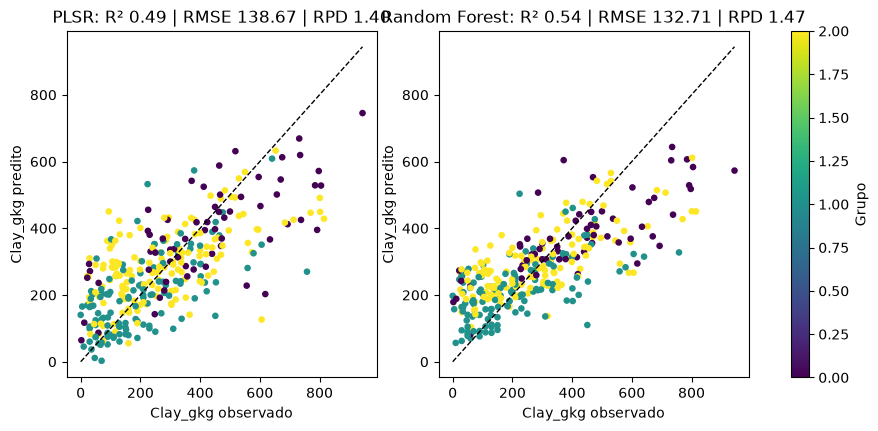

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
lim = [pred['observado'].min(), pred['observado'].max()]
for a, col, nome in zip(ax, ['pred_PLSR', 'pred_RF'], ['PLSR', 'Random Forest']):
    m = utils.avalia(pred['observado'], pred[col])
    sc = a.scatter(pred['observado'], pred[col], c=pred['cluster'], cmap='viridis', s=14)
    a.plot(lim, lim, 'k--', lw=1)
    a.set_xlabel(f'{alvo} observado'); a.set_ylabel(f'{alvo} predito')
    a.set_title(f"{nome}: R² {m['R2']:.2f} | RMSE {m['RMSE']:.2f} | RPD {m['RPD']:.2f}")
plt.colorbar(sc, ax=ax, label='Grupo')
utils.salva_figura(fig, '05_observado_predito.png'); plt.show()

## 2. Resíduos

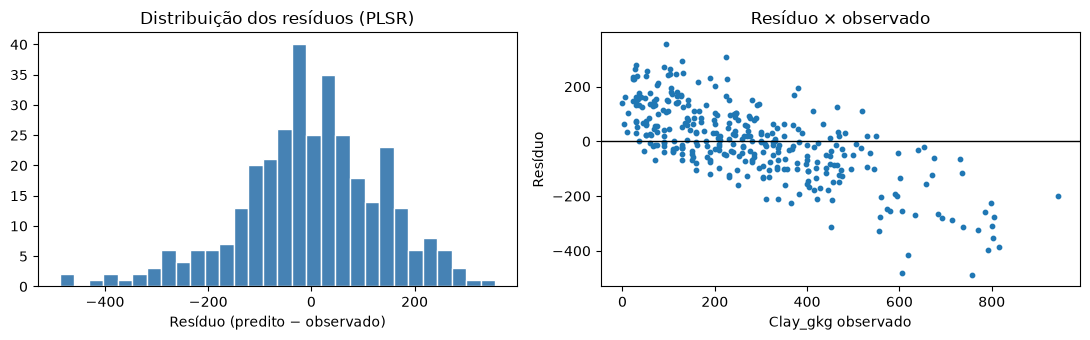

,n,RMSE_PLSR,RMSE_RF
cluster,,,
0,63.0,158.00,157.67
1,128.0,120.54,122.73
2,147.0,144.44,129.32


In [3]:
pred['residuo_PLSR'] = pred['pred_PLSR'] - pred['observado']
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(pred['residuo_PLSR'], bins=30, color='steelblue', edgecolor='white')
ax[0].set_xlabel('Resíduo (predito − observado)'); ax[0].set_title('Distribuição dos resíduos (PLSR)')
ax[1].scatter(pred['observado'], pred['residuo_PLSR'], s=10)
ax[1].axhline(0, color='k', lw=1)
ax[1].set_xlabel(f'{alvo} observado'); ax[1].set_ylabel('Resíduo'); ax[1].set_title('Resíduo × observado')
plt.tight_layout(); plt.show()

rmse_grupo = pred.groupby('cluster').apply(
    lambda g: pd.Series({'n': len(g), 'RMSE_PLSR': utils.avalia(g['observado'], g['pred_PLSR'])['RMSE'],
                         'RMSE_RF': utils.avalia(g['observado'], g['pred_RF'])['RMSE']}))
display(rmse_grupo.round(2))

## 3. Interpretação dos modelos

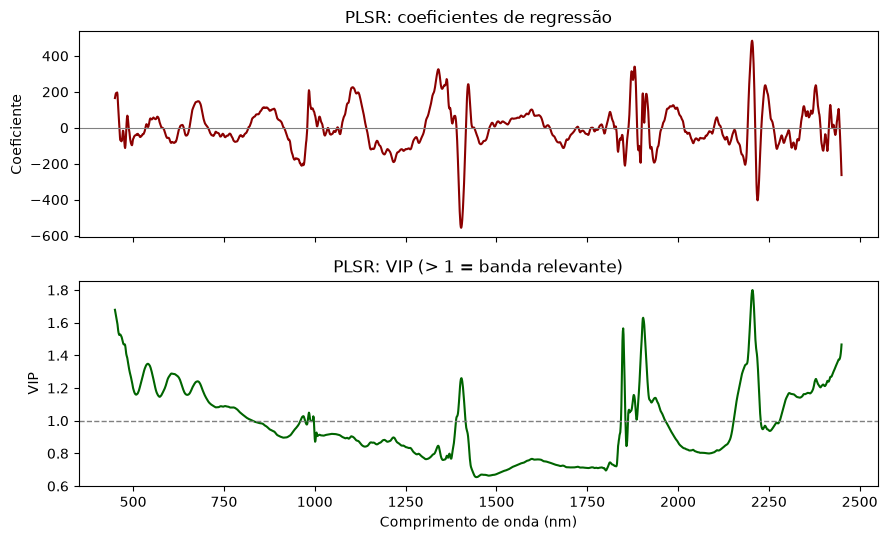

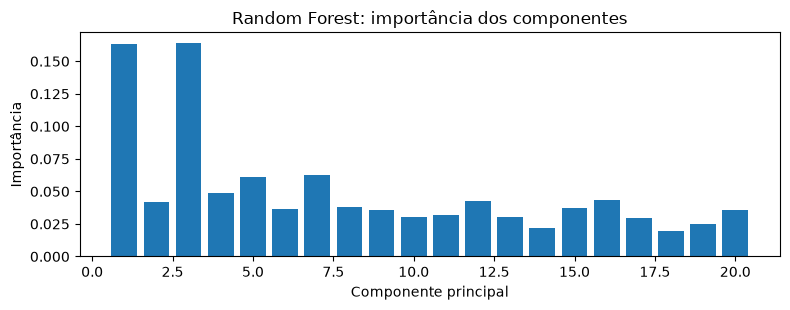

In [4]:
pls, wl_pp = modelo['pls'], modelo['wl_pp']
coef = pls.coef_.ravel()
vip = utils.vip(pls)

fig, ax = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
ax[0].plot(wl_pp, coef, color='darkred'); ax[0].axhline(0, color='gray', lw=0.8)
ax[0].set_ylabel('Coeficiente'); ax[0].set_title('PLSR: coeficientes de regressão')
ax[1].plot(wl_pp, vip, color='darkgreen'); ax[1].axhline(1, color='gray', ls='--', lw=1)
ax[1].set_ylabel('VIP'); ax[1].set_xlabel('Comprimento de onda (nm)'); ax[1].set_title('PLSR: VIP (> 1 = banda relevante)')
plt.tight_layout(); utils.salva_figura(fig, '05_plsr_coef_vip.png'); plt.show()

imp = modelo['rf'].named_steps['rf'].feature_importances_
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(range(1, len(imp) + 1), imp)
ax.set_xlabel('Componente principal'); ax.set_ylabel('Importância'); ax.set_title('Random Forest: importância dos componentes')
plt.tight_layout(); utils.salva_figura(fig, '05_rf_importancia.png'); plt.show()

## 4. Predição de amostras novas

Aplica **o mesmo pré-processamento** do modelo, reamostra se a grade espectral for diferente
e calcula T² e Q com o PCA do domínio ajustado na calibração.

In [9]:
if cfg.ARQUIVO_NOVAS is None:
    print('Nenhum arquivo de amostras novas configurado; etapa de predição ignorada.')
else:
    novas = pd.read_csv(cfg.ARQUIVO_NOVAS, encoding=cfg.ENCODING)
    cols_n, _ = utils.identificar_colunas(novas, cfg.PREFIXO)
    wl_n = utils.comprimentos_onda(cols_n, cfg.PREFIXO)
    wl_cal = modelo['wl']
    Xn = novas[cols_n].to_numpy(dtype=float)
    if len(wl_n) != len(wl_cal) or not np.allclose(wl_n, wl_cal):
        Xn = utils.reamostra(Xn, wl_n, wl_cal)
        print('Espectros reamostrados para a grade da calibração')

    _, Xn_pp = utils.preprocessa(Xn, wl_cal, modelo['tratamento'])
    t2_n, q_n = utils.t2_q(modelo['pca_dom'], Xn_pp)

    saida = pd.DataFrame({'id': novas[cfg.COL_ID],
                          f'{alvo}_PLSR': modelo['pls'].predict(Xn_pp).ravel(),
                          f'{alvo}_RF': modelo['rf'].predict(Xn_pp),
                          'T2': t2_n, 'Q': q_n})
    saida['dentro_dominio'] = (saida['T2'] <= modelo['lim_t2']) & (saida['Q'] <= modelo['lim_q'])
    saida.to_csv(cfg.PASTA / 'predicoes_novas_amostras.csv', index=False)
    print(f"Dentro do domínio: {saida['dentro_dominio'].sum()} de {len(saida)}")
    display(saida.head(10).round(3))

Nenhum arquivo de amostras novas configurado; etapa de predição ignorada.


## 5. Novas amostras sobre a nuvem de calibração

Esta visualização só é executada quando `ARQUIVO_NOVAS` está configurado.

In [7]:
if cfg.ARQUIVO_NOVAS is not None:
    sc_cal, sc_n = modelo['escores_cal'], modelo['pca_dom'].transform(Xn_pp)
    dentro = saida['dentro_dominio'].to_numpy()
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].scatter(sc_cal[:, 0], sc_cal[:, 1], s=8, c='lightgray', label='Calibração')
    ax[0].scatter(sc_n[dentro, 0], sc_n[dentro, 1], s=20, c='tab:blue', label='Novas (dentro)')
    ax[0].scatter(sc_n[~dentro, 0], sc_n[~dentro, 1], s=30, c='red', marker='x', label='Novas (fora)')
    ax[0].set_xlabel('PC1'); ax[0].set_ylabel('PC2'); ax[0].legend(); ax[0].set_title('Escores do PCA do domínio')
    ax[1].scatter(modelo['t2_cal'], modelo['q_cal'], s=8, c='lightgray', label='Calibração')
    ax[1].scatter(t2_n, q_n, s=20, c=np.where(dentro, 'tab:blue', 'red'), label='Novas')
    ax[1].axvline(modelo['lim_t2'], color='red', ls='--', lw=1); ax[1].axhline(modelo['lim_q'], color='red', ls='--', lw=1)
    ax[1].set_xlabel('T²'); ax[1].set_ylabel('Q'); ax[1].legend(); ax[1].set_title('T² × Q com os limites da calibração')
    plt.tight_layout(); utils.salva_figura(fig, '05_novas_vs_calibracao.png'); plt.show()
else:
    print('Visualização de novas amostras ignorada: nenhum arquivo foi configurado.')

Visualização de novas amostras ignorada: nenhum arquivo foi configurado.
